<a href="https://colab.research.google.com/github/RomanLuja/cafe_sale/blob/main/notebooks/eda_project_cafe_sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ☕ Аналіз продажів кафе: очищення даних та EDA
## Датасет: продажі кафе («брудні» дані)

У проєкті пройдено повний шлях аналітика: від «брудного» файлу з помилками до чистої таблиці, графіків і висновків для власника кафе.

**Структура:**
- **Частина 1.** Первинний огляд: що не так з даними.
- **Частина 2.** Очищення: виправляємо типи, відновлюємо пропуски, додаємо нові стовпці.
- **Частина 3.** EDA: товари, оплата, час, викиди, зв'язки між числами.
- **Частина 4.** Підсумковий звіт і рекомендації.

## Про дані

Датасет **Cafe Sales — Dirty Data for Cleaning Training** (Kaggle) містить 10 000 продажів кафе за 2023 рік. Дані синтетичні й навмисно «зіпсовані»: у них є пропуски, слова `ERROR` і `UNKNOWN` замість значень та інші проблеми.

| Стовпець | Що містить |
|---|---|
| `Transaction ID` | унікальний номер продажу |
| `Item` | товар: кава, чай, торт тощо |
| `Quantity` | кількість одиниць товару |
| `Price Per Unit` | ціна однієї одиниці, USD |
| `Total Spent` | сума продажу, USD (= кількість × ціна) |
| `Payment Method` | спосіб оплати |
| `Location` | де купили: у закладі чи на виніс |
| `Transaction Date` | дата продажу |

## ⚙️ Підготовка

Version moduls:
````
pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
seaborn==0.13.2
````

In [4]:
!pip show pandas

Name: pandas
Version: 2.2.3
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
All rights reserved.

Copyright (c) 2011-2023, Open source contributors.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

* Redistributions of source code must retain the above copyright notice, this
  list of conditions and the following disclaimer.

* Redistributions in binary form must reproduce the above copyright notice,
  this list of conditions and the following disclaimer in the documentation
  and/or other materials provided with the distribution.

* Neither the name of the copyright holder nor the names of its
  contributors may be u

In [5]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)

# Звідки читаємо «брудні» дані і куди збережемо чисті
FILE_IN = "https://raw.githubusercontent.com/RomanLuja/Cafe_sale/refs/heads/main/data/dirty_cafe_sales.csv"
FILE_OUT = "cafe_sales_clean.csv"

# Єдиний стиль для всіх графіків
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

print("Ready!")

pandas: 2.2.3
numpy: 2.4.6
matplotlib: 3.10.0
seaborn: 0.13.2
Ready!


---
# Частина 1. Первинний огляд

Перш ніж щось виправляти, треба зрозуміти, **що саме** не так з даними. У цій частині ми нічого не змінюємо по суті, лише дивимося й рахуємо.

## 1.1. Завантаження і перший погляд

In [6]:
# Читаємо файл у незмінний «зліпок»
df_original = pd.read_csv(FILE_IN)

# Робоча копія: далі працюємо лише з df
df = df_original.copy()

# Розмір таблиці
print(f"Рядків: {df.shape[0]}, стовпців: {df.shape[1]}")

# Перші 10 рядків
display(df.head(10))

# Типи стовпців і кількість заповнених значень
df.info()

Рядків: 10000, стовпців: 8


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


**Спостереження:** Числовими мають бути стовпці Quantity, Price Per Unit і Total Spent, а датою (datetime) має бути Transaction Date. Усі вони мають тип object (текст). Імовірна причина: у стовпцях разом із нормальними значеннями є сторонній текст (наприклад, “ERROR”, “UNKNOWN” або порожні рядки), тому pandas не зміг визначити числовий чи датовий тип і залишив усе текстом.


## 1.2. Що за «сміття» в даних?

In [7]:
df["Item"].value_counts(dropna=False)
df.Item.value_counts()

,count
Item,
Juice,1171
Coffee,1165
Salad,1148
Cake,1139
Sandwich,1131
Smoothie,1096
Cookie,1092
Tea,1089
UNKNOWN,344


In [8]:
for col in ["Item", "Payment Method", "Location"]:
  print(df[col].value_counts(dropna=False))

Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
NaN          333
ERROR        292
Name: count, dtype: int64
Payment Method
NaN               2579
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293
Name: count, dtype: int64
Location
NaN         3265
Takeaway    3022
In-store    3017
ERROR        358
UNKNOWN      338
Name: count, dtype: int64


In [9]:
converted = pd.to_numeric(df["Quantity"], errors = "coerce")
brocked_by_converted = converted.isna()
df.loc[ brocked_by_converted, "Quantity"].unique()

converted = pd.to_datetime(df["Transaction Date"], errors = "coerce")
brocked_by_converted = converted.isna()
df.loc[ brocked_by_converted, "Transaction Date"].unique()

for col in ["Quantity", "Price Per Unit", "Total Spent"]:
    bad = df[pd.to_numeric(df[col], errors="coerce").isna() & df[col].notna()]
    print(col, bad[col].unique())

dates = pd.to_datetime(df["Transaction Date"], errors="coerce")
mask = dates.isna() & df["Transaction Date"].notna()
print("Transaction Date", df.loc[mask, "Transaction Date"].unique())

display(df.isin(["ERROR", "UNKNOWN"]).sum())

Quantity ['ERROR' 'UNKNOWN']
Price Per Unit ['ERROR' 'UNKNOWN']
Total Spent ['ERROR' 'UNKNOWN']
Transaction Date ['ERROR' 'UNKNOWN']


,0
Transaction ID,0
Item,636
Quantity,341
Price Per Unit,354
Total Spent,329
Payment Method,599
Location,696
Transaction Date,301


**Спостереження:** Нечислові значення в стовпцях Quantity, Price Per Unit, Total Spent і Transaction Date — це лише службові слова “ERROR” і “UNKNOWN”. Значень, які можна виправити (число з комою або знаком валюти), не знайдено, тому errors="coerce" нічого корисного не втратить: ці слова просто стануть пропусками. Слова “ERROR” і “UNKNOWN” також трапляються в Item, Payment Method і Location (по кілька сотень разів у кожному), окрім звичайних порожніх клітинок.

## 1.3. Дублікати

In [10]:
# 1. Повні дублікати рядків
print(df.duplicated().sum())

# 2. Повтори номерів у Transaction ID
print(df["Transaction ID"].duplicated().sum())

# 3. Видаляємо повні дублікати й дивимось, скільки рядків лишилось
print(df.drop_duplicates())

0
0
     Transaction ID      Item Quantity Price Per Unit Total Spent  \
0       TXN_1961373    Coffee        2            2.0         4.0   
1       TXN_4977031      Cake        4            3.0        12.0   
2       TXN_4271903    Cookie        4            1.0       ERROR   
3       TXN_7034554     Salad        2            5.0        10.0   
4       TXN_3160411    Coffee        2            2.0         4.0   
...             ...       ...      ...            ...         ...   
9995    TXN_7672686    Coffee        2            2.0         4.0   
9996    TXN_9659401       NaN        3            NaN         3.0   
9997    TXN_5255387    Coffee        4            2.0         8.0   
9998    TXN_7695629    Cookie        3            NaN         3.0   
9999    TXN_6170729  Sandwich        3            4.0        12.0   

      Payment Method  Location Transaction Date  
0        Credit Card  Takeaway       2023-09-08  
1               Cash  In-store       2023-05-16  
2        Credit C

## 1.4. Огляд пропусків

,missing,pct
Location,3961,39.6
Payment Method,3178,31.8
Item,969,9.7
Price Per Unit,533,5.3
Total Spent,502,5.0
Quantity,479,4.8
Transaction Date,460,4.6


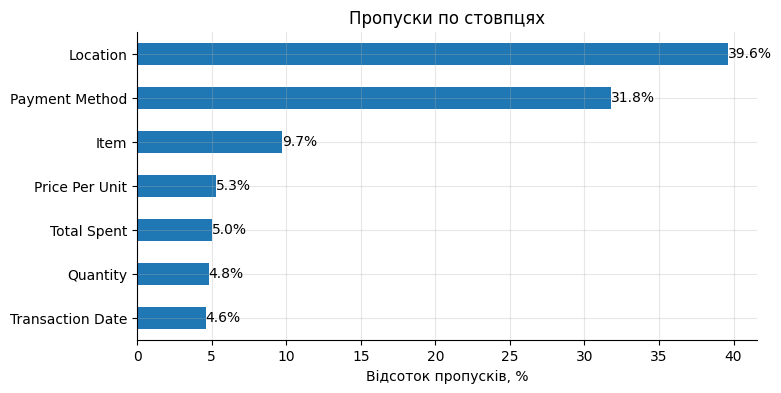

In [11]:
df = df.replace(["ERROR", "UNKNOWN"], np.nan)

missing = df.isna().sum()
pct = (missing / len(df) * 100).round(1)

missing_report = pd.DataFrame({"missing": missing, "pct": pct})
missing_report = missing_report[missing_report["missing"] > 0].sort_values("pct", ascending=False)
display(missing_report)

ax = missing_report["pct"].plot(kind="barh", figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.invert_yaxis()
ax.set_xlabel("Відсоток пропусків, %")
ax.set_title("Пропуски по стовпцях")
plt.show()


**Спостереження:** Найбільше пропусків у стовпцях Location (≈39.6%) і Payment Method (≈31.8%), далі йде Item (≈9.7%). Quantity, Price Per Unit, Total Spent і Transaction Date мають менше пропусків. Відновити можна числові стовпці: Total Spent = Quantity × Price Per Unit, тож будь-яке одне з трьох значень обчислюється з двох інших, якщо вони відомі. Item, імовірно, можна відновити за Price Per Unit, якщо в кожного товару своя ціна (це треба перевірити). Location і Payment Method відновити за іншими стовпцями не можна, бо вони з ними не пов'язані: для них лишається заповнення позначкою (наприклад, “Unknown”) або видалення рядків. Transaction Date за іншими стовпцями також не відновлюється.и

---
# Частина 2. Очищення даних

Головне правило очищення: **спочатку відновлюємо те, що можна порахувати точно, і лише потім заповнюємо решту**. Кожне вигадане значення спотворює аналіз, тому вигадуємо якомога менше.

## 2.1. Назви стовпців

In [12]:
df.columns = df.columns.str.lower().str.replace(" ", "_")
df.columns

Index(['transaction_id', 'item', 'quantity', 'price_per_unit', 'total_spent',
       'payment_method', 'location', 'transaction_date'],
      dtype='object')

## 2.2. Правильні типи даних

In [13]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"], errors="coerce")

for col in ["quantity", "price_per_unit", "total_spent"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Перевірка: типи і пропуски
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    10000 non-null  object        
 1   item              9031 non-null   object        
 2   quantity          9521 non-null   float64       
 3   price_per_unit    9467 non-null   float64       
 4   total_spent       9498 non-null   float64       
 5   payment_method    6822 non-null   object        
 6   location          6039 non-null   object        
 7   transaction_date  9540 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 625.1+ KB


## 2.3. Відновлюємо числа точно

Між числовими стовпцями є жорсткий зв'язок: **сума = кількість × ціна**. А ще в меню кафе кожен товар має фіксовану ціну. Отже, багато пропусків можна не вгадувати, а **порахувати**.

In [14]:
display(df.groupby("item")["price_per_unit"].nunique())
price_of_item = df.groupby("item")["price_per_unit"].median().to_dict()
print(price_of_item)

print()

# а) ціна за товаром
mask = df["price_per_unit"].isna() & df["item"].notna()
df.loc[mask, "price_per_unit"] = df.loc[mask, "item"].map(price_of_item)
print("Price from item:", mask.sum())

print()

# б) ціна = сума / кількість
mask = df["price_per_unit"].isna() & df["total_spent"].notna() & df["quantity"].notna()
df.loc[mask, "price_per_unit"] = df.loc[mask, "total_spent"] / df.loc[mask, "quantity"]
print("Price = total / quantity:", mask.sum())

print()

# в) кількість = сума / ціна
mask = df["quantity"].isna() & df["total_spent"].notna() & df["price_per_unit"].notna()
df.loc[mask, "quantity"] = (df.loc[mask, "total_spent"] / df.loc[mask, "price_per_unit"]).round()
print("Quantity = total / price:", mask.sum())

print()

# г) сума = кількість × ціна
mask = df["total_spent"].isna() & df["quantity"].notna() & df["price_per_unit"].notna()
df.loc[mask, "total_spent"] = df.loc[mask, "quantity"] * df.loc[mask, "price_per_unit"]
print("Total = quantity * price:", mask.sum())

print()

check = df.dropna(subset=["quantity", "price_per_unit", "total_spent"])
mismatch = (check["quantity"] * check["price_per_unit"]).round(2) != check["total_spent"].round(2)
print("Mismatches:", mismatch.sum())
display(df[["quantity", "price_per_unit", "total_spent"]].isna().sum())

,price_per_unit
item,
Cake,1
Coffee,1
Cookie,1
Juice,1
Salad,1
Sandwich,1
Smoothie,1
Tea,1


{'Cake': 3.0, 'Coffee': 2.0, 'Cookie': 1.0, 'Juice': 3.0, 'Salad': 5.0, 'Sandwich': 4.0, 'Smoothie': 4.0, 'Tea': 1.5}

Price from item: 479

Price = total / quantity: 48

Quantity = total / price: 456

Total = quantity * price: 479

Mismatches: 0


,0
quantity,23
price_per_unit,6
total_spent,23


## 2.4. Відновлюємо товар за ціною

Якщо товар невідомий, але відома ціна, можна спробувати визначити товар за ціною. Але це спрацює лише тоді, коли ціна належить **одному** товару.

In [15]:
known_items = df.dropna(subset=["item"])

known_items.groupby("price_per_unit")["item"].unique()

,item
price_per_unit,
1.0,[Cookie]
1.5,[Tea]
2.0,[Coffee]
3.0,"[Cake, Juice]"
4.0,"[Smoothie, Sandwich]"
5.0,[Salad]


In [16]:
n_items = known_items.groupby('price_per_unit')['item'].nunique()
unique_prices = n_items[n_items == 1].index
item_per_price = known_items[known_items['price_per_unit'].isin(unique_prices)].groupby('price_per_unit')['item'].first().to_dict()
item_per_price

{1.0: 'Cookie', 1.5: 'Tea', 2.0: 'Coffee', 5.0: 'Salad'}

In [17]:
mask = df['item'].isna() & df['price_per_unit'].isin(unique_prices)
df.loc[mask, 'item'] = df.loc[mask, 'price_per_unit'].map(item_per_price)

print(mask.sum())
print(df['item'].isna().sum())
df.loc[df['item'].isna(), 'price_per_unit'].value_counts(dropna=False)

489
480


,count
price_per_unit,
3.0,247
4.0,227
NaN,6


**Спостереження:** Ціни 3.0 і 4.0 неоднозначні і належать до [Cake, Juice] та ["Sandwich", "Smoothie"] відповідно. 480 рядків з такими цінами лишилися без товару.

## 2.5. Чи можна вгадати товар за іншими ознаками?

Для неоднозначної ціни треба обрати між двома товарами. Можливо, допоможуть інші стовпці: наприклад, торт частіше беруть у вихідні, а сік на виніс. **Перевірмо це на даних.**

In [18]:
df["is_weekend"] = df["transaction_date"].dt.dayofweek >= 5
df["is_weekend"].head()

,is_weekend
0,False
1,False
2,False
3,False
4,True


In [19]:
for pair_items in [['Cake', 'Juice'], ['Sandwich', 'Smoothie']]:
    pair = df[df['item'].isin(pair_items)]
    print("\n", "-" * 10, pair_items, "-" * 10)

    display((pair['item'].value_counts(normalize=True) * 100).round(1))
    print("-" * 10)
    display((pd.crosstab(pair["location"], pair["item"], normalize="index") * 100).round(1))
    print("-" * 10)
    pair_dated = pair[pair['transaction_date'].notna()]
    display((pd.crosstab(pair_dated["is_weekend"], pair_dated["item"], normalize="index") * 100).round(1))


 ---------- ['Cake', 'Juice'] ----------


,proportion
item,
Juice,50.7
Cake,49.3


----------


item,Cake,Juice
location,,
In-store,47.1,52.9
Takeaway,50.1,49.9


----------


item,Cake,Juice
is_weekend,,
False,49.5,50.5
True,47.8,52.2


... (2 outputs left out)

----------


item,Sandwich,Smoothie
location,,
In-store,53.5,46.5
Takeaway,53.2,46.8


----------


item,Sandwich,Smoothie
is_weekend,,
False,49.0,51.0
True,54.6,45.4


**Висновок:** Частки товарів майже не залежать від локації та вихідних. У парі Cake/Juice різниця за локацією становить 3.0 в.п. для Cake (47.1 % у закладі проти 50.1 % на винос), за вихідними 1.7 в.п. (49.5 % у будні проти 47.8 % у вихідні). У парі Sandwich/Smoothie різниця за локацією лише 0.3 в.п. (53.5 % проти 53.2 %), за вихідними 5.6 в.п. для Sandwich (49.0 % у будні проти 54.6 % у вихідні). Найбільше відхилення становить 5.6 в.п., а всі частки лежать у межах 45-55 %, тобто близько 50/50. За такими ознаками товар надійно вгадати не можна: навіть найкращий здогад помиляється майже у 45 % випадків, що лише трохи краще за підкидання монети. Тому пропуски в item не слід заповнювати припущенням.

## 2.6. Заповнюємо неоднозначні товари

Є три способи заповнити товар для неоднозначної ціни:

| Спосіб | Що відбувається | Проблема |
|---|---|---|
| завжди частіший товар | усі рядки з ціною 3.0 → `Juice` | `Juice` отримує всі ці продажі, `Cake` жодного: рейтинг товарів спотворюється |
| випадково, **пропорційно часткам** | 49% рядків → `Cake`, 51% → `Juice` | товар у конкретному рядку вгадано навмання, але загальні пропорції правильні |
| `"Unknown"` | товар не вигадуємо | ці рядки випадають з аналізу товарів |

Використаємо **другий** спосіб, бо нам важливі загальні продажі товарів, а не кожен окремий рядок. Але позначимо такі рядки, щоб пізніше перевірити, чи вплинуло заповнення на висновки.

In [20]:
rng = np.random.default_rng(42)

df['item_guessed'] = False

pairs = {
    3.0:	['Cake', 'Juice'],
    4.0:	['Smoothie', 'Sandwich']
}

for price, items in pairs.items():
    shares = df[df['item'].isin(items)]['item'].value_counts(normalize=True)[items]
    display(shares)
    mask = df['item'].isna() & (df['price_per_unit'] == price)
    df.loc[mask, 'item'] = rng.choice(items, size=mask.sum(), p=shares.values)
    df.loc[mask, 'item_guessed'] = True


print("-" * 10)
df['item'] = df['item'].fillna('Unknown')
df['item'].value_counts()

,proportion
item,
Cake,0.493074
Juice,0.506926


,proportion
item,
Smoothie,0.492142
Sandwich,0.507858


----------


,count
item,
Juice,1295
Coffee,1291
Salad,1272
Cake,1262
Sandwich,1248
Cookie,1213
Tea,1207
Smoothie,1206
Unknown,6


## 2.7. Спосіб оплати і локація

**Навіщо `"Unknown"`, а не найчастіше значення (мода):** у `payment_method` пропущено майже третину значень, а в `location` близько 40%. Якщо заповнити їх модою, один спосіб оплати отримає кілька тисяч чужих продажів і штучно «переможе» решту. `"Unknown"` чесно показує, що ми цього не знаємо.

In [21]:
df['payment_method'] = df['payment_method'].fillna("Unknown")
df['location'] = df['location'].fillna("Unknown")

df.head()

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date,is_weekend,item_guessed
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,False,False
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,False,False
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19,False,False
3,TXN_7034554,Salad,2.0,5.0,10.0,Unknown,Unknown,2023-04-27,False,False
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,True,False


In [22]:
for col in ['item', 'payment_method', 'location']:
    print(col, df[col].nunique(), '-->', df[col].str.strip().str.lower().nunique())

item 9 --> 9
payment_method 4 --> 4
location 3 --> 3


## 2.8. Видаляємо те, що не відновити

In [23]:
befor = len(df)
befor

10000

In [24]:
df = df.dropna(subset=['transaction_date', 'quantity', 'price_per_unit', 'total_spent']).copy()
df['quantity'] = df['quantity'].astype(int)

print("Rows removed now:", befor - len(df))
print("Rows in original:", len(df_original), "| after cleaning:", len(df))
print("Loss, %:", round((len(df_original) - len(df)) / len(df_original) * 100, 1))
print("Missing values left:", df.isna().sum().sum())

Rows removed now: 486
Rows in original: 10000 | after cleaning: 9514
Loss, %: 4.9
Missing values left: 0


## 2.9. Нові ознаки з дати і збереження

In [25]:
print(df.columns.tolist())

['transaction_id', 'item', 'quantity', 'price_per_unit', 'total_spent', 'payment_method', 'location', 'transaction_date', 'is_weekend', 'item_guessed']


In [26]:
df.columns

df['month'] = df['transaction_date'].dt.month               # номер місяця (1–12)
df['month_name'] = df['transaction_date'].dt.month_name()   # назва місяця
df['weekday'] = df['transaction_date'].dt.dayofweek         # номер дня тижня (0 = понеділок)
df['weekday_name'] = df['transaction_date'].dt.day_name()   # назва дня тижня
df['is_weekend'] = df['weekday'].isin([5, 6])               # True для суботи й неділі

df[['transaction_date', 'month', 'month_name', 'weekday', 'weekday_name', 'is_weekend']].head()

,transaction_date,month,month_name,weekday,weekday_name,is_weekend
0,2023-09-08,9,September,4,Friday,False
1,2023-05-16,5,May,1,Tuesday,False
2,2023-07-19,7,July,2,Wednesday,False
3,2023-04-27,4,April,3,Thursday,False
4,2023-06-11,6,June,6,Sunday,True


In [27]:
df.to_csv(FILE_OUT, index=False)
print("Saved:", FILE_OUT)

Saved: cafe_sales_clean.csv


# Частина 3. Дослідницький аналіз (EDA)

Тепер дані чисті, і можна шукати відповіді на питання власника кафе.

## 3.1. Які товари продаються найкраще?

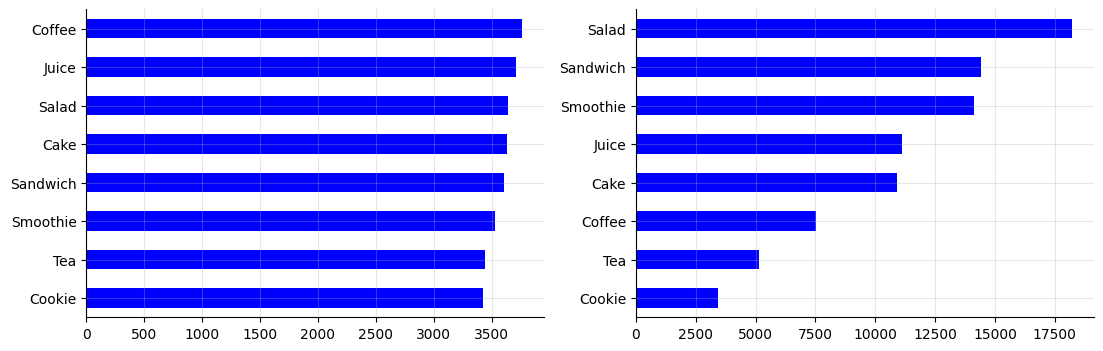

In [28]:
known = df[df['item'] != 'Unknown']

units_by_item = known.groupby('item')['quantity'].sum().sort_values()
revenue_by_item = known.groupby('item')['total_spent'].sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
units_by_item.plot(kind='barh', ax=axes[0], color="blue")
axes[0].set_ylabel("")

revenue_by_item.plot(kind='barh', ax=axes[1], color="blue")
axes[1].set_ylabel("")

plt.show()

In [29]:
without_guessed = df[(df['item'] != 'Unknown') & ~df['item_guessed']]

compare = pd.DataFrame({
    'with_guessed': known.groupby('item')['total_spent'].sum(),
    'without_guessed': without_guessed.groupby('item')['total_spent'].sum()
}).sort_values('with_guessed', ascending=False)

compare

,with_guessed,without_guessed
item,,
Salad,18220.0,18220.0
Sandwich,14412.0,13068.0
Smoothie,14108.0,12776.0
Juice,11118.0,10023.0
Cake,10890.0,9834.0
Coffee,7532.0,7532.0
Tea,5161.5,5161.5
Cookie,3427.0,3427.0


**Висновок:** Без вгаданих рядків рейтинг не змінився: Salad лідирує, далі Sandwich, Smoothie, Juice, Cake, Coffee, Tea, Cookie. Salad, Coffee, Tea і Cookie не мали вгаданих рядків, тому їхні значення однакові. Sandwich, Smoothie, Juice і Cake втратили приблизно 9–10 %, але порядок зберігся, бо розриви між сусідніми товарами більші за ці втрати. Найближчі пари (Juice і Cake) зблизились: різниця зменшилась з 228 до 189.

## 3.2. Спосіб оплати і локація

In [30]:
print(df['payment_method'].unique())
print(df['location'].unique())

['Credit Card' 'Cash' 'Unknown' 'Digital Wallet']
['Takeaway' 'In-store' 'Unknown']


payment_method
Unknown           26328.0
Digital Wallet    19534.0
Cash              19531.0
Credit Card       19476.0
Name: total_spent, dtype: float64

payment_method
Unknown           31.02
Digital Wallet    23.02
Cash              23.01
Credit Card       22.95
Name: total_spent, dtype: float64

location
Unknown     33630.0
In-store    25852.0
Takeaway    25386.0
Name: total_spent, dtype: float64

location
Unknown     39.63
In-store    30.46
Takeaway    29.91
Name: total_spent, dtype: float64


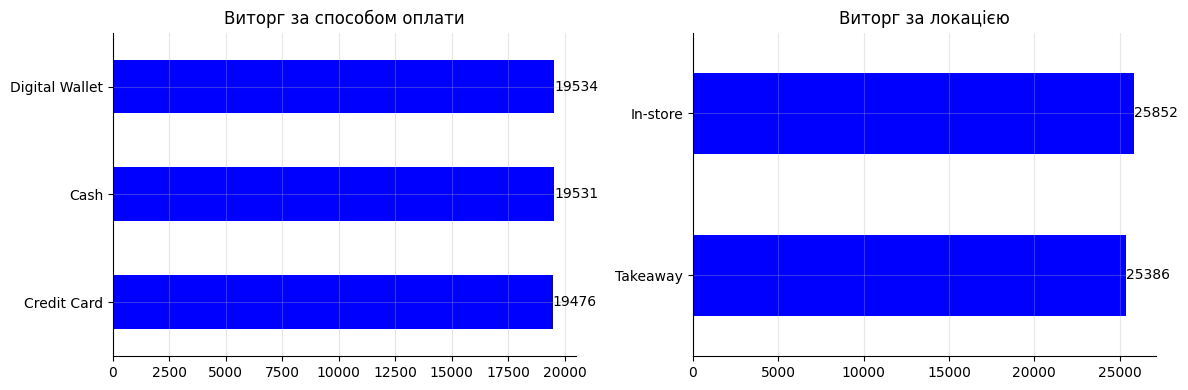

In [31]:
# виторг за кожним значенням
rev_payment = df.groupby('payment_method')['total_spent'].sum().sort_values(ascending=False)
rev_location = df.groupby('location')['total_spent'].sum().sort_values(ascending=False)

# частки у відсотках (разом з "Unknown")
share_payment = rev_payment / rev_payment.sum() * 100
share_location = rev_location / rev_location.sum() * 100

print(rev_payment.round(0), share_payment.round(2), sep="\n\n")

print()

print(rev_location.round(0), share_location.round(2), sep="\n\n")

# два графіки поруч, без "Unknown"
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rev_payment.drop("Unknown").sort_values().plot.barh(ax=axes[0], color="blue", title="Виторг за способом оплати")
axes[0].bar_label(axes[0].containers[0], fmt="%.0f")
axes[0].set_ylabel("")

rev_location.drop("Unknown").sort_values().plot.barh(ax=axes[1],  color="blue", title="Виторг за локацією")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


**Висновок:**

- Продажі з невідомим способом оплати становлять 31.02 % виторгу, а з невідомою локацією 39.63 %. Це дуже велика частка: в обох випадках "Unknown" був би найбільшим стовпчиком, тому його прибрано з графіків.
- Серед відомих способів оплати найбільше приносить Digital Wallet (23.02 %). Cash має 23.01 %, Credit Card 22.95 %. Різниця між першим і останнім становить 0.07 процентного пункту, тому явного лідера немає: усі три способи приносять майже однаково.
- В закладі (In-store) купують трохи більше: 30.46 % виторгу проти 29.91 % на виніс (Takeaway). Різниця становить 0.55 процентного пункту.
- Частка невідомих значень велика: 31.02 % виторгу за способом оплати і 39.63 % за локацією. Вона набагато більша за різниці між відомими значеннями (0.07 і 0.55 процентного пункту), тому висновки про лідера слід вважати орієнтовними.

## 3.3. Продажі в часі

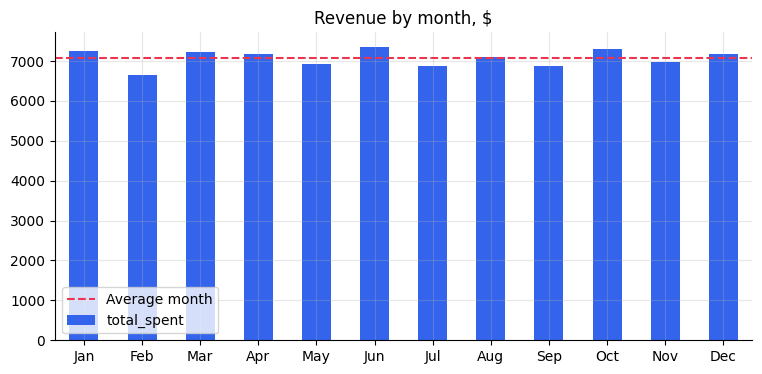

In [32]:
month_name = {1: "Jan", 2: "Feb", 3: 'Mar', 4: "Apr", 5: "May", 6: "Jun",
              7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}

monthly = df.groupby("month")['total_spent'].sum()
monthly.index = monthly.index.map(month_name)
monthly.plot(kind="bar", rot=0, color='#3464eb')
plt.axhline(monthly.mean(), color='#eb344f', linestyle="--", label="Average month")
plt.title("Revenue by month, $")
plt.xlabel('')
plt.legend()
plt.show()

In [33]:

# Середній чек по днях тижня - hw
y_names = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}


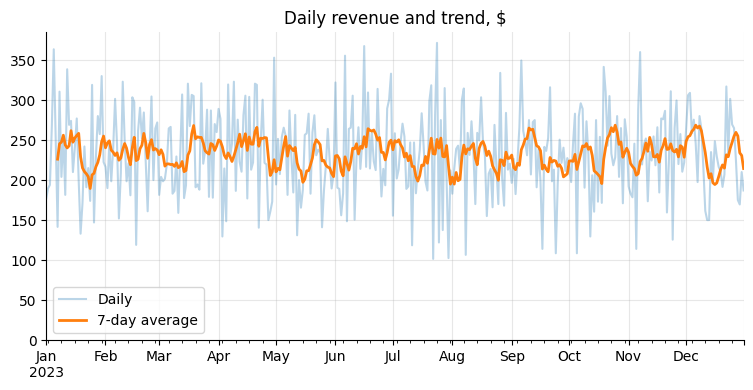

In [34]:
daily = df.groupby('transaction_date')['total_spent'].sum()
daily.plot(alpha=0.3, label="Daily")
daily.rolling(7).mean().plot(linewidth=2, label="7-day average")
plt.title("Daily revenue and trend, $")
plt.xlabel('')
plt.ylim(bottom=0)
plt.legend()
plt.show()

In [35]:
# ---------- Питання 1: найкращий і найслабший місяць ----------
avg = monthly.mean()                          # середній місячний виторг
dev = (monthly - avg) / avg * 100             # відхилення кожного місяця від середнього, %

best_m = monthly.idxmax()                     # назва місяця з найбільшим виторгом
worst_m = monthly.idxmin()                    # назва місяця з найменшим виторгом

print(f"Середній місяць: {avg:.2f} $")
print(f"Найкращий: {best_m}, {monthly[best_m]:.0f} $, {dev[best_m]:+.2f} % від середнього")
print(f"Найслабший: {worst_m}, {monthly[worst_m]:.0f} $, {dev[worst_m]:+.2f} % від середнього")

# ---------- Питання 2: середній чек, вихідні проти буднів ----------
check = df.groupby('is_weekend')['total_spent'].mean()   # False = будні, True = вихідні
diff = check[True] - check[False]                        # різниця в $
diff_pct = diff / check[False] * 100                     # різниця в % від буднів

print()
print(f"Середній чек у будні: {check[False]:.2f} $")
print(f"Середній чек у вихідні: {check[True]:.2f} $")
print(f"Різниця: {diff:+.2f} $ ({diff_pct:+.2f} %)")

# ---------- Питання 3: сезонний тренд ----------
print()
print("Відхилення місяців від середнього, %:")
print(dev.round(2))
print(f"Діапазон відхилень: від {dev.min():+.2f} % до {dev.max():+.2f} %")

# 7-денне середнє денного виторгу: мінімум і максимум за рік
roll = daily.rolling(7).mean()
print(f"7-денне середнє: мін {roll.min():.0f} $, макс {roll.max():.0f} $")

# середній виторг за день і кількість днів у кожному місяці
per_day = daily.groupby(daily.index.month).agg(['count', 'mean']).round(2)
per_day.index = per_day.index.map(month_name)
print()
print(per_day)

# середній виторг за день по порах року
season_map = {12: "Winter", 1: "Winter", 2: "Winter",
              3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer",
              9: "Autumn", 10: "Autumn", 11: "Autumn"}
seasons = daily.groupby(daily.index.month.map(season_map)).mean().round(2)
print()
print(seasons)

Середній місяць: 7072.38 $
Найкращий: Jun, 7353 $, +3.97 % від середнього
Найслабший: Feb, 6644 $, -6.06 % від середнього

Середній чек у будні: 8.93 $
Середній чек у вихідні: 8.89 $
Різниця: -0.04 $ (-0.41 %)

Відхилення місяців від середнього, %:
month
Jan    2.57
Feb   -6.06
Mar    2.03
Apr    1.51
May   -1.98
Jun    3.97
Jul   -2.76
Aug    0.28
Sep   -2.85
Oct    3.42
Nov   -1.49
Dec    1.35
Name: total_spent, dtype: float64
Діапазон відхилень: від -6.06 % до +3.97 %
7-денне середнє: мін 190 $, макс 269 $

                  count    mean
transaction_date               
Jan                  31  234.00
Feb                  28  237.29
Mar                  31  232.77
Apr                  30  239.30
May                  31  223.63
Jun                  30  245.10
Jul                  31  221.85
Aug                  31  228.79
Sep                  30  229.03
Oct                  31  235.94
Nov                  30  232.23
Dec                  31  231.23

transaction_date
Autumn    232.44
S

**Висновок:**

- Найкращий місяць червень: 7 353 USD, це на 3.97 % більше за середній місяць (7 072.38 USD). Найслабший лютий: 6 644 USD, це на 6.06 % менше за середній місяць.
- Середній чек у вихідні практично не відрізняється від буднів: у будні 8.93 USD, у вихідні 8.89 USD. У вихідні чек на 0.04 USD нижчий, тобто на 0.41 %. Підстав посилювати персонал саме у вихідні за середнім чеком немає.
- Чіткого сезонного тренду немає. Відхилення місяців від середнього лежать у межах від −6.06 % до +3.97 %, високі й низькі місяці чергуються без зв'язку з порами року. Середній виторг за день по порах року майже однаковий: зима 234.07 USD, осінь 232.44 USD, весна 231.82 USD, літо 231.77 USD. Різниця між найвищим і найнижчим значенням лише 2.30 USD. 7-денне середнє протягом року коливається від 190 USD до 269 USD без стійкого зростання чи спаду. Низький лютий пояснюється тим, що в ньому лише 28 днів: середній виторг за день у лютому (237.29 USD) не нижчий, ніж у січні (234.00 USD) чи березні (232.77 USD).

## 3.4. Викиди

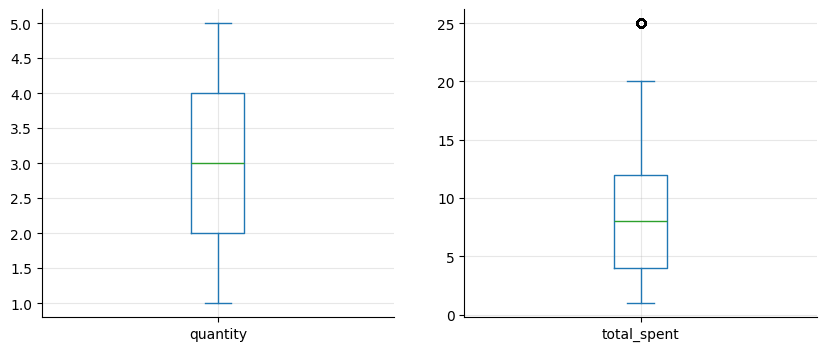

In [36]:
df[["quantity", "total_spent"]].plot(kind="box", subplots=True, layout=(1, 2), figsize=(10, 4))
plt.show()

In [37]:
q1 = df['total_spent'].quantile(0.25)
q3 = df['total_spent'].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

outliners = df[(df['total_spent'] < low) | (df['total_spent'] > high)]

print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print(f"Normal range: {low} - {high}")
print("Outlines:", len(outliners))

outliners.groupby(['item', 'quantity', 'price_per_unit'])['total_spent'].agg(['count', 'first'])

Q1: 4.0 Q3: 12.0 IQR: 8.0
Normal range: -8.0 - 24.0
Outlines: 259


,,,count,first
item,quantity,price_per_unit,,
Salad,5,5.0,259,25.0


**Рішення щодо викидів:** За правилом IQR (Q1 = 4.0, Q3 = 12.0, IQR = 8.0) нормальний діапазон становить від −8.0 до 24.0. Викидами виявилися 259 покупок, і всі вони однакові: Salad, 5 одиниць по 5.0 USD, разом 25.0 USD. Це лише на 1.0 USD вище верхньої межі.

Це не помилки в даних, а звичайні реальні покупки: сума збігається з кількістю, помноженою на ціну (5 × 5.0 = 25.0). Видаляти їх не можна, бо ми втратимо справжній виторг. Обмежувати до 24.0 USD теж не потрібно, бо це спотворило б реальну суму чека. Тому викиди залишаємо.

## 3.5. Зв'язки між числами

In [38]:
table = df[["quantity", "price_per_unit", "total_spent"]].corr()

table.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}")

,quantity,price_per_unit,total_spent
quantity,1.00,0.01,0.70
price_per_unit,0.01,1.00,0.65
total_spent,0.70,0.65,1.00


**Інтерпретація:**

| Пара | Кореляція | Сила зв'язку | Пояснення |
|---|---|---|---|
| `quantity` ↔ `total_spent` | 0.70 | сильний додатний | Чим більше одиниць у замовленні, тим більша сума чека |
| `price_per_unit` ↔ `total_spent` | 0.65 | 	помірний або сильний додатний | Чим дорожчий товар, тим більша сума чека, але зв'язок трохи слабший, ніж з кількістю |
| `quantity` ↔ `price_per_unit` | 0.01 | зв'язку немає  | Кількість і ціна за одиницю не залежать одна від одної: люди купують однакову кількість і дешевих, і дорогих товарів. |

# Частина 4. Звіт для власника кафе

In [39]:
# Ваш код тут
total_revenue = df['total_spent'].sum()
n_transactions = len(df)
avg_check = df['total_spent'].mean()
top_item_original = without_guessed.groupby('item')['total_spent'].sum().idxmax()
top_payment = df[df['payment_method'] != 'Unknown'].groupby('payment_method')['total_spent'].sum().idxmax()


known_location = df.groupby('location')['total_spent'].sum().drop('Unknown').sort_values(ascending=False)

location_share = (known_location / known_location.sum() * 100).round(1)


print("CAFE SALES 2023: SUMMARY")
print("Total revenue, $:", round(total_revenue, 2))
print("Transactions:", n_transactions)
print("Average check, $:", round(avg_check, 2))
print("Top item by revenue (original data):", top_item_original)
print("Top payment method (known only):", top_payment)
print()
print("Revenue share by location, %:\n", pd.DataFrame(location_share))

CAFE SALES 2023: SUMMARY
Total revenue, $: 84868.5
Transactions: 9514
Average check, $: 8.92
Top item by revenue (original data): Salad
Top payment method (known only): Digital Wallet

Revenue share by location, %:
           total_spent
location             
In-store         50.5
Takeaway         49.5


**Висновки для власника кафе:**

1. За 2023 рік кафе заробило 84 868.5 USD на 9 514 продажах, середній чек 8.92 USD.
2. Salad дає найбільший виторг, це перше місце з 8 товарів. Без вгаданих рядків рейтинг не змінюється.
3. Серед відомих способів оплати Digital Wallet має 23.02 % виторгу, Cash 23.01 %, Credit Card 22.95 %. Різниця між першим і останнім 0.07 процентного пункту, тому явного лідера немає.
4. Серед відомих локацій In-store дає 50.5 % виторгу, Takeaway 49.5 %, тобто майже порівну.
5. Виторг стабільний: відхилення місяців від середнього від −6.06 % до +3.97 %, середній чек у будні 8.93 USD, у вихідні 8.89 USD.

**Рекомендації:**
- Тримати Salad у постійній наявності, бо це товар з найбільшим виторгом.
- Записувати спосіб оплати й локацію для кожного продажу, щоб частка невідомих (31.02 % і 39.63 % виторгу) зменшилась.

**Обмеження даних:**
- Спосіб оплати невідомий для 31.02 % виторгу, локація невідома для 39.63 %. Частки за ними пораховано лише серед відомих значень, тому висновки про лідерів орієнтовні.
- Частина назв товарів у даних відновлена (вгадана), тому товар-лідер визначено за рядками без вгаданих значень.
- 259 покупок по 25.0 USD (Salad, 5 одиниць) формально є викидами, але це реальні продажі, тому їх залишено в розрахунках.